# Exercício 5 · Não paramétricos e bootstrap: as bikes da Pedala

**Disciplina 4 · Testes de Hipótese e Experimentação · Pós-graduação em Ciência de Dados e IA · UNIPDS**

**GABARITO** · com prompts, código e leituras comentadas.

## O contexto

A **Pedala** opera um sistema de bicicletas compartilhadas numa cidade: os usuários retiram uma bike numa estação, pedalam e devolvem em outra. Todos os dados vêm do sistema (viagens, tempo de uso, avaliações no app).

O time de Operações rodou quatro estudos. Em todos, há algo que torna o teste t uma escolha ruim: amostras pequenas, valores extremos, notas de 1 a 5 ou uma pergunta que não é sobre a média.

| Parte | Pergunta | Arquivo | Técnica |
|:---|:---|:---|:---|
| 1 | O piloto de **reserva pelo app** aumentou as viagens? | `piloto_reserva.csv` | Mann-Whitney |
| 2 | A **nova sinalização** mudou o uso das estações? | `sinalizacao.csv` | Wilcoxon pareado |
| 3 | Os três **modelos de bike** têm a mesma avaliação? | `avaliacao_modelos.csv` | Kruskal-Wallis |
| 4 | O **reposicionamento noturno** deixa as bikes menos tempo paradas? | `bikes_reposicionamento.csv` | Bootstrap |

### Como usar este gabarito

Cada passo tem o **prompt** usado, o código gerado e a **leitura** do resultado. Os prompts são um exemplo: o importante é que digam **o que** a análise precisa fazer, não **como** codificar. **Todos os testes são bicaudais, com α = 5%.**

## Parte 0 · Preparação

**Prompt para a IA**

> Vou fazer testes não paramétricos e bootstrap em Python. Prepare o ambiente com as bibliotecas que vamos usar para manipular dados, fazer gráficos e fazer estatística (testes não paramétricos, correção para múltiplas comparações e reamostragem). Use funções prontas sempre que possível e escreva um código simples, para iniciantes. O nível de significância é de 5%.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

ALPHA = 0.05

## Parte 1 · O piloto de reserva pelo app

A Pedala testou um recurso que permite **reservar uma bike pelo app** até 10 minutos antes de chegar à estação. Das 20 estações de um bairro, **10 foram sorteadas** para o piloto e 10 ficaram como controle. A métrica é o número de **viagens na semana** por estação.

Um detalhe: a estação E20, do piloto, fica ao lado de um estádio que recebeu um show naquela semana.

- **H0:** as viagens nas estações com reserva e sem reserva vêm da mesma distribuição.
- **Ha:** um dos grupos tende a ter mais viagens.

**Prompt para a IA**

> Leia o arquivo piloto_reserva.csv. mostre as 5 primeiras linhas.Para cada grupo (controle e reserva), mostre o número de estações, a média, a mediana e o desvio-padrão das viagens na semana. Faça um gráfico de pontos com as viagens de cada estação, separadas por grupo.

   estacao_id     grupo  viagens_semana
0         E01  controle             118
1         E02  controle              96
2         E03  controle             142
3         E04  controle             105
4         E05  controle             131
5         E06  controle              88
6         E07  controle             124
7         E08  controle             110
8         E09  controle              99
9         E10  controle             137
10        E11   reserva             139
11        E12   reserva             158
12        E13   reserva             121
13        E14   reserva             172
14        E15   reserva             147
15        E16   reserva             165
16        E17   reserva             134
17        E18   reserva             152
18        E19   reserva             129
19        E20   reserva             612
          count   mean  median    std
grupo                                
controle     10  115.0   114.0   18.3
reserva      10  192.9   149.5  148.1


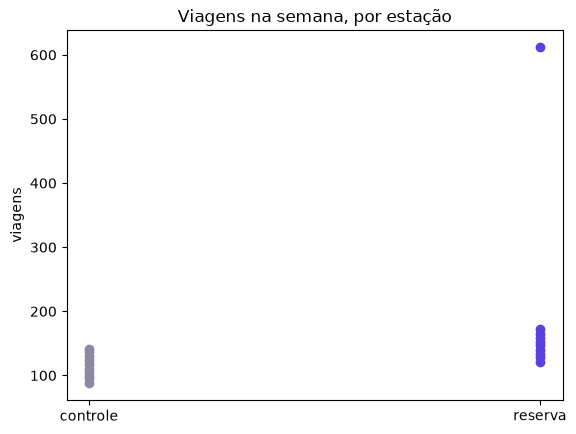

In [ ]:
p1 = pd.read_csv(r"C:\Users\renat\Downloads\piloto_reserva.csv")
print(p1)
print(p1.groupby("grupo")["viagens_semana"].agg(["count", "mean", "median", "std"]).round(1))

controle = p1.loc[p1["grupo"] == "controle", "viagens_semana"]
reserva = p1.loc[p1["grupo"] == "reserva", "viagens_semana"]

plt.scatter(["controle"] * len(controle), controle, color="#8C89A3")
plt.scatter(["reserva"] * len(reserva), reserva, color="#5B3FE0")
plt.title("Viagens na semana, por estação")
plt.ylabel("viagens")
plt.show()

> **Leitura.** As estações com reserva fizeram, em média, 192,9 viagens, contra 115,0 do controle. Mas a média do piloto é puxada por uma única estação: a E20, com 612 viagens na semana do show. Sem ela, nenhuma estação do piloto passa de 172. A mediana conta outra história, mais estável: 149,5 contra 114,0. O desvio-padrão do piloto (148) é 8 vezes o do controle (18), tudo por causa de um ponto.

**Prompt para a IA**

> Aplique o teste de normalidade de Shapiro-Wilk às viagens de cada grupo e mostre os p-valores. Faça também um QQ-plot de cada grupo, lado a lado.

Shapiro-Wilk · controle: p = 0.805
Shapiro-Wilk · reserva:  p = 0.0000017


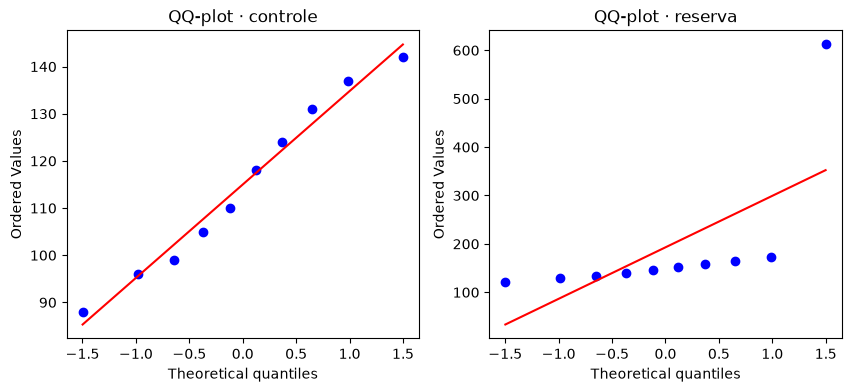

In [ ]:
print(f"Shapiro-Wilk · controle: p = {stats.shapiro(controle).pvalue:.3f}")
print(f"Shapiro-Wilk · reserva:  p = {stats.shapiro(reserva).pvalue:.7f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(controle, plot=ax[0])
ax[0].set_title("QQ-plot · controle")
stats.probplot(reserva, plot=ax[1])
ax[1].set_title("QQ-plot · reserva")
plt.show()

> **Leitura.** No grupo com reserva, o Shapiro rejeita a normalidade (p ≈ 0,000002), e o QQ-plot mostra por quê: nove pontos perto da reta e um muito acima, a estação do show. No controle, p = 0,81 e os pontos ficam perto da reta, mas, com 10 estações, isso diz pouco: o teste tem pouco poder com amostras tão pequenas. Com 10 observações por grupo e um valor extremo, o TLC não dá conta: o teste t não é confiável aqui.

**Prompt para a IA**

> Compare os dois grupos com o teste t de Welch (bicaudal) e com o teste de Mann-Whitney (bicaudal). Mostre os p-valores. Para o Mann-Whitney, mostre também a estatística U e a proporção de pares, uma estação de cada grupo, em que a estação com reserva teve mais viagens (U dividido pelo número de pares).

In [ ]:
welch = stats.ttest_ind(reserva, controle, equal_var=False)
print(f"t de Welch: p = {welch.pvalue:.3f}")

mw = stats.mannwhitneyu(reserva, controle, alternative="two-sided")
n_pares = len(reserva) * len(controle)
print(f"Mann-Whitney: U = {mw.statistic:.0f} de {n_pares} pares · p = {mw.pvalue:.4f}")
print(f"Pares em que a estação com reserva teve mais viagens: {mw.statistic / n_pares:.0%}")



t de Welch: p = 0.132
Mann-Whitney: U = 90 de 100 pares · p = 0.0028
Pares em que a estação com reserva teve mais viagens: 90%


> **Leitura.** Os dois testes discordam:
>
> O **t de Welch**: Com o show, o sinal aumenta porque o 612 puxa a média para cima. Mas o ruído aumenta muito mais: um único valor tão distante dos outros multiplica o desvio-padrão do grupo por quase 9 (de 17 para 148). Como o desvio-padrão entra no denominador, o t cai de 3,86 para 1,65, e o teste deixa de ver a diferença.

> Com o 612 no meio, o teste t “acha” que as estações do piloto variam enormemente entre si. Se elas variam tanto, uma diferença de muitas viagens poderia ser acaso. Só que, na verdade, nove das dez estações variam pouco; é uma só que destoa.

> O **Mann-Whitney** não tem esse problema porque trabalha com postos: o 612 vale “a maior”, exatamente como valeria se fosse 180. Ele não infla nada.

> **Conclusão:** as estações com **reserva** tendem a ter mais viagens. Se você sortear uma estação com reserva e uma sem, **a com reserva tem 90% de chance de ter feito mais viagens**. Se a reserva não fizesse diferença (H0), esperaríamos que cada lado ganhasse metade dos duelos, ou seja, 50%. Os 90% ficam muito longe disso, e daí vem o p = 0,0028.

## Parte 2 · A nova sinalização

A Pedala instalou uma sinalização nova (placas na rua indicando a estação mais próxima) em **12 estações**. Para cada uma, comparou as viagens nas 4 semanas **antes** com as 4 semanas **depois** da instalação, mesmo período do mês.

Aqui os dados são **pareados**: cada estação é medida duas vezes. O que importa é a mudança dentro de cada estação, não a diferença entre estações grandes e pequenas.

- **H0:** as diferenças depois − antes se distribuem em torno de zero.
- **Ha:** as diferenças tendem a ser positivas ou negativas.

**Prompt para a IA**

> Leia o arquivo sinalizacao.csv. Calcule a diferença de viagens (depois menos antes) de cada estação, mostre a tabela com as diferenças, quantas estações aumentaram e a mediana das diferenças. Depois, aplique o teste de Wilcoxon de postos sinalizados para dados pareados (bicaudal) e, para comparar, o teste t pareado, com o intervalo de confiança de 95% da diferença média.

In [ ]:
p2 = pd.read_csv("sinalizacao.csv")
p2["diferenca"] = p2["viagens_depois"] - p2["viagens_antes"]
print(p2)
print(f"\nEstações que aumentaram: {(p2['diferenca'] > 0).sum()} de {len(p2)}")
print(f"Mediana das diferenças: {p2['diferenca'].median():.0f} viagens")

wilcoxon = stats.wilcoxon(p2["viagens_depois"], p2["viagens_antes"])
print(f"\nWilcoxon pareado: p = {wilcoxon.pvalue:.4f}")

t_par = stats.ttest_rel(p2["viagens_depois"], p2["viagens_antes"])
ic = t_par.confidence_interval()
print(f"t pareado: p = {t_par.pvalue:.5f} · IC 95% da diferença média: {ic.low:.1f} a {ic.high:.1f}")

   estacao_id  viagens_antes  viagens_depois  diferenca
0         S01             84              93          9
1         S02            132             141          9
2         S03             61              70          9
3         S04             97              95         -2
4         S05            150             166         16
5         S06             73              82          9
6         S07            118             129         11
7         S08             66              75          9
8         S09            104             112          8
9         S10             89             101         12
10        S11            140             147          7
11        S12             77              80          3

Estações que aumentaram: 11 de 12
Mediana das diferenças: 9 viagens

Wilcoxon pareado: p = 0.0010
t pareado: p = 0.00005 · IC 95% da diferença média: 5.5 a 11.2


> **Leitura.** **11 das 12 estações** aumentaram as viagens depois da sinalização, com mediana de +9 viagens. A única que caiu (S04) caiu só 2 viagens. O Wilcoxon rejeita H0 com p = 0,001: se a sinalização não fizesse nada, aumentos e quedas deveriam se equilibrar, e eles não se equilibram.
>
> O t pareado concorda (p = 0,00005), com IC de +5,5 a +11,2 viagens. Aqui os dois testes chegam à mesma conclusão porque não há valores extremos: as diferenças são todas pequenas e parecidas. **A sinalização aumentou o uso das estações.**
>
> **Por que pareado?** As estações têm tamanhos muito diferentes (de 61 a 150 viagens). Um teste para grupos independentes compararia "estações antes" com "estações depois" e se perderia nessa variação entre estações. O pareado olha só a mudança dentro de cada uma.

## Parte 3 · O reposicionamento noturno

À noite, uma van pode levar bikes de estações vazias para as mais movimentadas. A operação custa caro, e o time quer saber se ela vale a pena. A Pedala sorteou **60 bikes** para o reposicionamento e **60 de controle** e mediu, durante um mês, o **tempo médio que cada bike ficou parada** entre um uso e outro, em horas.

**Por que bootstrap?** Algumas bikes ficam esquecidas por dias em estações remotas, o que puxa a média. A pergunta de negócio é sobre a **bike típica** da frota: quanto tempo ela fica parada? Isso pede a **mediana**, e a diferença entre duas medianas não tem uma fórmula simples de intervalo de confiança. O bootstrap resolve isso por simulação.

**Prompt para a IA**

> Leia o arquivo bikes_reposicionamento.csv. Para cada grupo, mostre a média, a mediana, os quartis e o máximo das horas paradas, e quantas bikes ficaram paradas em média mais de 60 horas. Faça um histograma das horas paradas de cada grupo, lado a lado.

    bike_id          grupo  horas_parada
0      B001       controle          17.7
1      B002       controle          24.5
2      B003       controle           3.5
3      B004       controle          10.3
4      B005       controle          17.4
..      ...            ...           ...
115    B116  reposicionada           6.4
116    B117  reposicionada           8.5
117    B118  reposicionada           4.8
118    B119  reposicionada           8.8
119    B120  reposicionada           5.9

[120 rows x 3 columns]
               count  mean   std  min  25%   50%   75%    max
grupo                                                        
controle        60.0  16.8  18.6  3.5  9.3  12.5  17.5  118.4
reposicionada   60.0  18.6  35.9  3.4  5.5   8.1  11.3  165.3

Bikes paradas mais de 60 h:
grupo
controle         3
reposicionada    5
dtype: int64


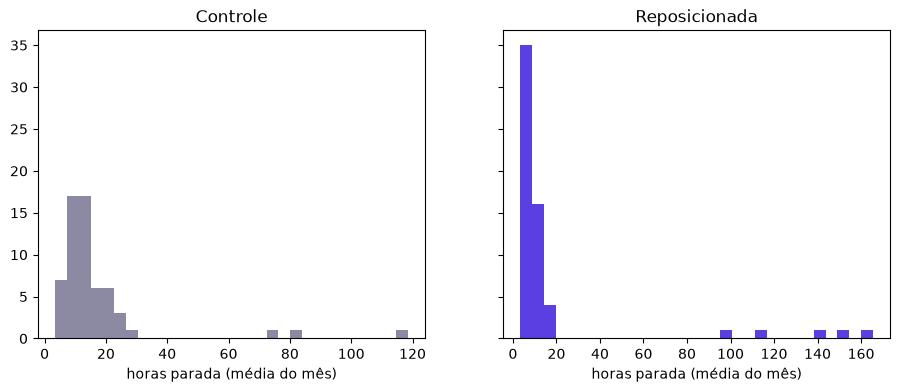

In [ ]:
p4 = pd.read_csv(r"C:\Users\renat\Downloads\bikes_reposicionamento.csv")
print(p4)
print(p4.groupby("grupo")["horas_parada"].describe().round(1))
print()
print("Bikes paradas mais de 60 h:")
print(p4[p4["horas_parada"] > 60].groupby("grupo").size())

ctrl = p4.loc[p4["grupo"] == "controle", "horas_parada"].values
repo = p4.loc[p4["grupo"] == "reposicionada", "horas_parada"].values

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ax[0].hist(ctrl, bins=30, color="#8C89A3")
ax[0].set_title("Controle")
ax[1].hist(repo, bins=30, color="#5B3FE0")
ax[1].set_title("Reposicionada")
for a in ax:
    a.set_xlabel("horas parada (média do mês)")
plt.show()

> **Leitura.** A bike típica do grupo reposicionado fica menos tempo parada: mediana de **8,1 horas**, contra **12,5** do controle, e os quartis também caem (de 9,3 a 17,5 h no controle, de 5,5 a 11,3 h no reposicionado). Mas as médias apontam para o lado contrário: 18,6 horas no reposicionado contra 16,8 no controle. O motivo são as bikes "esquecidas": 5 no reposicionado e 3 no controle ficaram, em média, mais de 60 horas paradas, uma delas quase 7 dias. Elas não dependem do reposicionamento (ficam em estações remotas, fora da rota da van), mas dominam a média.

**Prompt para a IA**

> Faça o bootstrap da diferença das medianas entre os grupos (reposicionada menos controle): sorteie, com reposição, o mesmo número de bikes de cada grupo, calcule a diferença das medianas e repita 5.000 vezes. Mostre a diferença observada, o intervalo de confiança de 95% pelos percentis 2,5 e 97,5 e um histograma das 5.000 diferenças, com o intervalo marcado.

[-3.  -5.2 -4.9 ... -4.4 -5.9 -3.6]
Diferença observada das medianas: -4.4 h
IC 95% (bootstrap): -6.4 a -2.3 h


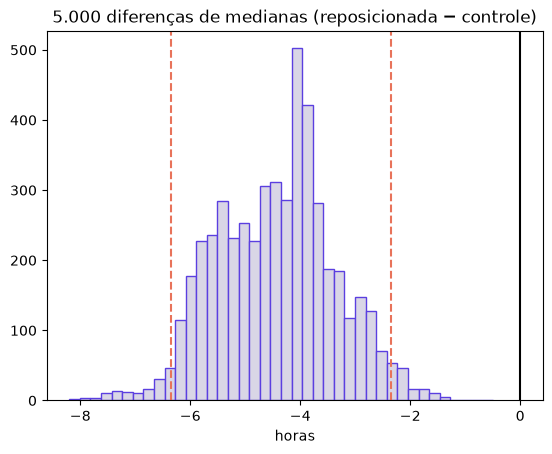

In [ ]:
rng = np.random.default_rng(42)
n_reamostras = 5000

diferencas = []
for _ in range(n_reamostras):
    amostra_repo = rng.choice(repo, size=len(repo), replace=True)
    amostra_ctrl = rng.choice(ctrl, size=len(ctrl), replace=True)
    diferencas.append(np.median(amostra_repo) - np.median(amostra_ctrl))
diferencas = np.array(diferencas)

print(diferencas)

observada = np.median(repo) - np.median(ctrl)
ic_inf, ic_sup = np.percentile(diferencas, [2.5, 97.5])
print(f"Diferença observada das medianas: {observada:+.1f} h")
print(f"IC 95% (bootstrap): {ic_inf:.1f} a {ic_sup:.1f} h")

plt.hist(diferencas, bins=40, color="#D9D6E6", edgecolor="#5B3FE0")
plt.axvline(ic_inf, color="#E8735A", linestyle="--")
plt.axvline(ic_sup, color="#E8735A", linestyle="--")
plt.axvline(0, color="black")
plt.title("5.000 diferenças de medianas (reposicionada − controle)")
plt.xlabel("horas")
plt.show()

> **Leitura.** A mediana do tempo parado caiu **4,4 horas** com o reposicionamento, com IC de 95% de **−6,4 a −2,3 horas**. O intervalo inteiro fica abaixo de zero: a bike típica do grupo reposicionado fica, plausivelmente, de 2 a 6 horas a menos parada.
>
> O histograma mostra o que o bootstrap fez: simulou 5.000 experimentos "parecidos com o nosso", reamostrando as próprias bikes. A variação entre eles é a nossa estimativa de quanto a diferença das medianas mudaria se repetíssemos o estudo.

[ 8.16       12.77833333 -7.00333333 ... -5.00166667  5.30166667
  2.79666667]
Diferença observada das médias: +1.8 h
IC 95% (bootstrap): -7.7 a 12.7 h


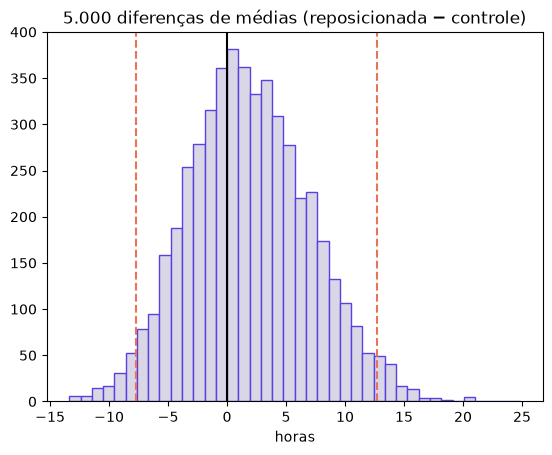

In [ ]:
rng = np.random.default_rng(42)
n_reamostras = 5000

diferencas = []
for _ in range(n_reamostras):
    amostra_repo = rng.choice(repo, size=len(repo), replace=True)
    amostra_ctrl = rng.choice(ctrl, size=len(ctrl), replace=True)
    diferencas.append(np.mean(amostra_repo) - np.mean(amostra_ctrl))
diferencas = np.array(diferencas)

print(diferencas)

observada = np.mean(repo) - np.mean(ctrl)
ic_inf, ic_sup = np.percentile(diferencas, [2.5, 97.5])
print(f"Diferença observada das médias: {observada:+.1f} h")
print(f"IC 95% (bootstrap): {ic_inf:.1f} a {ic_sup:.1f} h")

plt.hist(diferencas, bins=40, color="#D9D6E6", edgecolor="#5B3FE0")
plt.axvline(ic_inf, color="#E8735A", linestyle="--")
plt.axvline(ic_sup, color="#E8735A", linestyle="--")
plt.axvline(0, color="black")
plt.title("5.000 diferenças de médias (reposicionada − controle)")
plt.xlabel("horas")
plt.show()

**Prompt para a IA**

> Para comparar, faça o teste t de Welch para a diferença das médias (reposicionada menos controle) e mostre a diferença, o p-valor e o intervalo de confiança de 95%.

In [ ]:
welch = stats.ttest_ind(repo, ctrl, equal_var=False)
ic = welch.confidence_interval()
print(f"Diferença das médias: {repo.mean() - ctrl.mean():+.1f} h")
print(f"t de Welch: p = {welch.pvalue:.2f} · IC 95%: {ic.low:.1f} a {ic.high:.1f} h")

Diferença das médias: +1.8 h
t de Welch: p = 0.74 · IC 95%: -8.6 a 12.1 h


> **Leitura.** Pela média, o resultado é inconclusivo: +1,8 hora, com p = 0,74 e IC de −8,6 a +12,1 horas, um intervalo enorme. As poucas bikes esquecidas inflam a variância e dominam a média.
>
> **Os dois resultados não se contradizem; eles respondem perguntas diferentes.** A mediana diz o que acontece com a **bike típica**: ela fica menos tempo parada. A média mistura isso com as bikes esquecidas em estações remotas, um problema que o reposicionamento não resolve (elas estão fora da rota da van).

## Parte 4 · As recomendações

| Estudo | Recomendação |
|:---|:---|
| Reserva pelo app | **Expandir.** As estações com reserva tendem a ter mais viagens (Mann-Whitney p = 0,003; ficam à frente em 90% dos pares; diferença típica de +34 viagens por semana). O t de Welch inconclusivo era efeito de uma única estação com show. |
| Sinalização | **Instalar nas outras estações.** 11 das 12 estações aumentaram o uso, com mediana de +9 viagens (Wilcoxon p = 0,001). |
| Reposicionamento | **Manter**, se o custo couber: a bike típica fica de 2 a 6 horas a menos parada (IC da diferença das medianas). E tratar à parte as bikes esquecidas em estações remotas, que o reposicionamento não alcança e que dominam a média. |